# 과제 2: YOLO11 Fine-tuning — 한국 지폐 인식 (1000원 / 5000원 / 10000원)

**응용 시나리오:** 시각장애인을 위한 지폐 인식 및 총 금액 계산

**노트북 구성**
1. 데이터 수집 (동영상 프레임 추출) + YOLO-World 자동 라벨링
2. 실험 A — 사전학습 모델(전이학습) fine-tuning
3. 실험 B — 사전학습 없이 처음부터 학습 (비교용)
4. 성능 비교 (mAP, 학습 곡선)
5. 오류 분석 (잘못 탐지한 테스트 이미지)
6. 동영상 객체 탐지 + 추적 + 궤적(trajectory) + 총 금액 표시
7. 결과 저장

> Colab 메뉴: 런타임 → 런타임 유형 변경 → **T4 GPU** 선택 후 실행

In [ ]:
!pip install -q ultralytics
import ultralytics
ultralytics.checks()

## 0. Google Drive 연결 (Colab 연결이 끊겨도 결과가 남도록)

In [ ]:
from google.colab import drive
import os

try:
    drive.mount('/content/drive')
    SAVE_DIR = '/content/drive/MyDrive/ML_assignment2'
    print("Google Drive 마운트 성공!")
except Exception as e:
    print("Google Drive 마운트 실패. 로컬 디렉터리를 사용합니다:", e)
    SAVE_DIR = '/content/local_save_dir'

os.makedirs(SAVE_DIR, exist_ok=True)
print(f"결과 저장 경로: {SAVE_DIR}")

## 1. 데이터 수집 — 동영상에서 프레임 추출 + 자동 라벨링
**수집 방법:** 지폐 종류별로 동영상을 1개씩 촬영 (한 영상에는 해당 지폐 1장만 등장)
→ 일정 간격으로 프레임 추출 → Open-vocabulary 탐지 모델 **YOLO-World**로 `banknote` 위치를 자동 탐지
→ 영상이 곧 클래스이므로 bounding box에 해당 클래스 번호 부여.

Google Drive `MyDrive/ML_assignment2/videos/` 폴더에 다음 파일을 업로드하세요:
`1000won.mp4`, `5000won.mp4`, `10000won.mp4` (학습용), `demo.mp4` (세 지폐가 함께 나오는 시연용, **학습에 사용하지 않음**)

In [ ]:
import cv2, glob, os, shutil, random
CLASSES = ['1000won', '5000won', '10000won']
VIDEO_DIR = f'{SAVE_DIR}/videos'
N_PER_CLASS = 150          # 클래스당 추출 프레임 수
RAW = '/content/raw_frames'

for ci, c in enumerate(CLASSES):
    src = (glob.glob(f'{VIDEO_DIR}/{c}.*') or [None])[0]
    assert src, f'{c} 동영상이 없습니다'
    os.makedirs(f'{RAW}/{c}', exist_ok=True)
    cap = cv2.VideoCapture(src)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    step = max(1, total // N_PER_CLASS)
    i = k = 0
    while True:
        ok, f = cap.read()
        if not ok:
            break
        if i % step == 0:
            h, w = f.shape[:2]
            s = 1280 / max(h, w)
            if s < 1:
                f = cv2.resize(f, (int(w * s), int(h * s)))
            cv2.imwrite(f'{RAW}/{c}/{k:04d}.jpg', f)
            k += 1
        i += 1
    print(c, '프레임', k, '장')

In [ ]:
# YOLO-World로 자동 라벨링 (지폐 1장 → 가장 신뢰도 높은 box 1개)
from ultralytics import YOLO
world = YOLO('yolov8x-worldv2.pt')
world.set_classes(['banknote', 'paper money', 'bill'])

DATA_DIR = '/content/dataset'
labeled = {c: [] for c in CLASSES}
for ci, c in enumerate(CLASSES):
    for p in sorted(glob.glob(f'{RAW}/{c}/*.jpg')):
        r = world.predict(p, conf=0.05, verbose=False)[0]
        if len(r.boxes) == 0:
            continue
        j = int(r.boxes.conf.argmax())
        x, y, w, h = r.boxes.xywhn[j].tolist()
        if not (0.02 < w * h < 0.95):      # 너무 작거나 화면 전체인 box 제외
            continue
        labeled[c].append((p, f'{ci} {x:.6f} {y:.6f} {w:.6f} {h:.6f}'))
    print(c, f'라벨 성공 {len(labeled[c])} / {len(glob.glob(f"{RAW}/{c}/*.jpg"))}')

In [3]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, glob, cv2, random, yaml
SAVE_DIR = '/content/drive/MyDrive/ML_assignment2'
VIDEO_DIR = f'{SAVE_DIR}/videos'
CLASSES = ['1000won', '5000won', '10000won']
DATA_DIR = '/content/dataset'
shutil.unpack_archive(f'{SAVE_DIR}/dataset.zip', DATA_DIR)
yaml_path = f'{DATA_DIR}/data.yaml'
for sp in ['train', 'valid', 'test']:
    imgs = os.listdir(f'{DATA_DIR}/{sp}/images')
    print(sp, len(imgs), {c: sum(i.startswith(c + '_') for i in imgs) for c in CLASSES})

Mounted at /content/drive
train 468 {'1000won': 147, '5000won': 178, '10000won': 143}
valid 133 {'1000won': 42, '5000won': 50, '10000won': 41}
test 66 {'1000won': 21, '5000won': 25, '10000won': 20}


In [ ]:
# 학습/검증/테스트 분할 — 연속 프레임은 서로 비슷하므로 랜덤이 아닌 '시간 구간'으로 분할 (데이터 누수 방지)
shutil.rmtree(DATA_DIR, ignore_errors=True)
for sp in ['train', 'valid', 'test']:
    os.makedirs(f'{DATA_DIR}/{sp}/images'); os.makedirs(f'{DATA_DIR}/{sp}/labels')

for c, items in labeled.items():
    n = len(items)
    for idx, (p, line) in enumerate(items):
        sp = 'train' if idx < 0.7 * n else ('valid' if idx < 0.9 * n else 'test')
        name = f'{c}_{os.path.basename(p)}'
        shutil.copy(p, f'{DATA_DIR}/{sp}/images/{name}')
        open(f'{DATA_DIR}/{sp}/labels/{name[:-4]}.txt', 'w').write(line + '\n')

import yaml
yaml_path = f'{DATA_DIR}/data.yaml'
yaml.safe_dump({'path': DATA_DIR, 'train': 'train/images', 'val': 'valid/images',
                'test': 'test/images', 'names': {i: c for i, c in enumerate(CLASSES)}}, open(yaml_path, 'w'))
for sp in ['train', 'valid', 'test']:
    print(sp, len(os.listdir(f'{DATA_DIR}/{sp}/images')), '장')

# 데이터 세트 백업 (보고서·GitHub용)
shutil.make_archive(f'{SAVE_DIR}/dataset', 'zip', DATA_DIR)

In [ ]:
# 자동 라벨 품질 확인 — box가 지폐를 잘 감싸는지 눈으로 확인
import matplotlib.pyplot as plt
samples = random.sample(glob.glob(f'{DATA_DIR}/train/images/*'), 12)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, p in zip(axes.flat, samples):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    ci, x, y, w, h = map(float, open(p.replace('/images/', '/labels/')[:-4] + '.txt').read().split())
    cv2.rectangle(img, (int((x - w/2) * W), int((y - h/2) * H)), (int((x + w/2) * W), int((y + h/2) * H)), (255, 0, 0), 4)
    ax.imshow(img); ax.set_title(CLASSES[int(ci)]); ax.axis('off')
plt.savefig(f'{SAVE_DIR}/label_check.png', dpi=100, bbox_inches='tight'); plt.show()

## 2. 실험 A — 전이학습 (COCO 사전학습 YOLO11n)
- 사전학습된 특징 추출부(backbone: C3k2, SPPF, C2PSA)를 그대로 활용하고
  출력 클래스 수(3개)에 맞게 탐지 헤드를 바꿔 학습합니다.
- **지폐는 색이 클래스를 구분하는 핵심 특징**이므로 색조(hue) 증강을 끄고(`hsv_h=0`),
  좌우 반전된 지폐는 현실에 없으므로 `fliplr=0` 으로 설정했습니다.

In [7]:
from ultralytics import YOLO

COMMON = dict(data=yaml_path, epochs=50, imgsz=640, batch=16,
              hsv_h=0.0, fliplr=0.0, seed=0, project='runs', exist_ok=True)

model_A = YOLO('yolo11n.pt')              # 사전학습 가중치
model_A.train(name='pretrained', **COMMON)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pretrained, nbs=64, nms=None, opset=None, optimize=False, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x77faecfe2660>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

## 3. 실험 B — 사전학습 없이 처음부터 학습 (같은 설정)
전이학습의 효과를 확인하기 위한 비교 실험입니다.

In [ ]:
model_B = YOLO('yolo11n.yaml')            # 구조만, 가중치는 랜덤 초기화
model_B.train(name='scratch', pretrained=False, **COMMON)

## 4. 성능 비교 (테스트 세트)

In [ ]:
import pandas as pd

rows = []
for name in ['pretrained', 'scratch']:
    # Correcting the path to target the correct runs subdirectory
    best_weight_path = f'runs/detect/runs/{name}/weights/best.pt'
    m = YOLO(best_weight_path)
    r = m.val(data=yaml_path, split='test', project='runs', name=f'test_{name}', exist_ok=True)
    rows.append({
        '실험': name,
        'Precision': round(r.box.mp, 3),
        'Recall': round(r.box.mr, 3),
        'mAP50': round(r.box.map50, 3),
        'mAP50-95': round(r.box.map, 3)
    })
    # 클래스별 mAP50-95
    for i, c in enumerate(r.box.ap_class_index):
        rows[-1][f'AP {m.names[int(c)]}'] = round(r.box.maps[int(c)], 3)

compare = pd.DataFrame(rows)
display(compare)

In [ ]:
# 학습 곡선 비교 (epoch별 validation mAP50)
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
for name in ['pretrained', 'scratch']:
    df = pd.read_csv(f'runs/{name}/results.csv')
    df.columns = df.columns.str.strip()
    plt.plot(df['epoch'], df['metrics/mAP50(B)'], label=name)
plt.xlabel('epoch'); plt.ylabel('val mAP50'); plt.title('Transfer learning vs From scratch')
plt.legend(); plt.grid(alpha=.3)
plt.savefig('runs/compare_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Ultralytics가 자동 생성한 그래프 확인 (보고서에 사용)
from IPython.display import Image, display
display(Image('runs/pretrained/results.png', width=900))
display(Image('runs/test_pretrained/confusion_matrix.png', width=600))

## 5. 오류 분석 — 모델이 틀린 테스트 이미지 찾기
정답 라벨과 예측 클래스 목록이 다른 이미지를 모아서 확인합니다.
(어떤 지폐끼리 혼동했는지, 어떤 상황에서 놓쳤는지 보고서에 분석)

In [ ]:
import os, cv2
best = YOLO('runs/pretrained/weights/best.pt')
names = best.names

errors = []
for p in sorted(glob.glob(f"{DATA_DIR}/test/images/*")):
    lbl = os.path.splitext(p.replace('/images/', '/labels/'))[0] + '.txt'
    gt = sorted(int(l.split()[0]) for l in open(lbl) if l.strip()) if os.path.exists(lbl) else []
    r = best.predict(p, conf=0.5, verbose=False)[0]
    pred = sorted(r.boxes.cls.int().tolist())
    if gt != pred:
        errors.append((p, [names[i] for i in gt], [names[i] for i in pred], r))

print(f'테스트 {len(glob.glob(DATA_DIR + "/test/images/*"))}장 중 오류 {len(errors)}장')

n = min(6, len(errors))
if n:
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes = [axes] if n == 1 else axes
    for ax, (p, gt, pred, r) in zip(axes, errors[:n]):
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
        ax.set_title(f'GT: {gt}\nPred: {pred}', fontsize=9); ax.axis('off')
    plt.savefig('runs/error_cases.png', dpi=150, bbox_inches='tight')
    plt.show()

## 6. 동영상: 객체 탐지 + 추적 + 궤적 + 총 금액
직접 촬영한 동영상(5~10초)을 Colab 왼쪽 파일 창에 업로드하고 파일명을 맞춰주세요.
- 추적기: ByteTrack (`model.track`, `persist=True` 로 프레임 간 ID 유지)
- 각 ID의 중심점 이동 경로를 저장하여 궤적(trajectory)을 그림
- 현재 화면에 보이는 지폐의 금액을 합산하여 표시

In [9]:
import numpy as np
from collections import defaultdict, deque

VIDEO_IN = f'{VIDEO_DIR}/demo.mp4'      # 학습에 사용하지 않은 시연 영상
VIDEO_OUT = '/content/result_raw.mp4'
VALUE = {'1000won': 1000, '5000won': 5000, '10000won': 10000}
COLORS = {'1000won': (255, 120, 0), '5000won': (0, 80, 255), '10000won': (0, 200, 0)}  # BGR

cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))

track_hist = defaultdict(lambda: deque(maxlen=int(fps * 2)))   # 최근 2초 궤적
trajectory_log = []                                            # (frame, id, class, x, y) 저장

frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = best.track(frame, persist=True, tracker='bytetrack.yaml', conf=0.5, verbose=False)[0]
    vis = r.plot(line_width=2)
    total, count = 0, defaultdict(int)

    if r.boxes.id is not None:
        xywh = r.boxes.xywh.cpu().numpy()
        ids = r.boxes.id.int().cpu().tolist()
        clss = r.boxes.cls.int().cpu().tolist()
        for (x, y, w, h), tid, c in zip(xywh, ids, clss):
            cname = names[c]
            total += VALUE.get(cname, 0); count[cname] += 1
            track_hist[tid].append((int(x), int(y)))
            trajectory_log.append((frame_idx, tid, cname, float(x), float(y)))
            pts = np.array(track_hist[tid], np.int32).reshape(-1, 1, 2)
            cv2.polylines(vis, [pts], False, COLORS.get(cname, (0, 255, 255)), 3)

    # 상단 정보 패널
    cv2.rectangle(vis, (0, 0), (W, 70), (0, 0, 0), -1)
    cv2.putText(vis, f'TOTAL: {total:,} KRW', (15, 48), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 3)
    info = '  '.join(f'{k}x{v}' for k, v in count.items())
    cv2.putText(vis, info, (int(W * 0.55), 45), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (200, 200, 200), 2)

    out.write(vis)
    frame_idx += 1

cap.release(); out.release()
pd.DataFrame(trajectory_log, columns=['frame', 'id', 'class', 'x', 'y']).to_csv('/content/trajectory.csv', index=False)
print('프레임 수:', frame_idx)

NameError: name 'best' is not defined

In [ ]:
# 브라우저/GitHub에서 재생되도록 H.264로 변환 + README용 GIF 생성
!ffmpeg -y -loglevel error -i /content/result_raw.mp4 -vcodec libx264 -pix_fmt yuv420p /content/result.mp4
!ffmpeg -y -loglevel error -i /content/result.mp4 -vf "fps=10,scale=480:-1" /content/result.gif

from IPython.display import HTML
from base64 import b64encode
mp4 = open('/content/result.mp4', 'rb').read()
HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{b64encode(mp4).decode()}" type="video/mp4"></video>')

## 7. 결과 저장 (Google Drive) → GitHub에 업로드할 파일
- `best.pt` (학습 모델), `result.mp4`, `result.gif`, `trajectory.csv`
- `results.png`, `confusion_matrix.png`, `compare_curve.png`, `error_cases.png`, `compare.csv`

In [2]:
import shutil
import os

compare.to_csv('runs/compare.csv', index=False)
files = [
    'runs/detect/runs/pretrained/weights/best.pt',
    'runs/detect/runs/pretrained/results.png',
    'runs/detect/runs/test_pretrained/confusion_matrix.png',
    'runs/compare_curve.png',
    'runs/error_cases.png',
    'runs/compare.csv',
    '/content/result.mp4',
    '/content/result.gif',
    '/content/trajectory.csv'
]

for f in files:
    if os.path.exists(f):
        shutil.copy(f, SAVE_DIR)
        print('저장 완료:', os.path.basename(f))
    else:
        print('파일을 찾을 수 없음:', f)

NameError: name 'compare' is not defined

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


1000won: 성공 210 / 211  실패원인 {'화면 전체': 1}
5000won: 성공 253 / 254  실패원인 {'화면 전체': 1}
10000won: 성공 239 / 252  실패원인 {'화면 전체': 5, '탐지 없음': 8}
train 493 {'1000won': 147, '5000won': 178, '10000won': 168}
valid 140 {'1000won': 42, '5000won': 50, '10000won': 48}
test 69 {'1000won': 21, '5000won': 25, '10000won': 23}


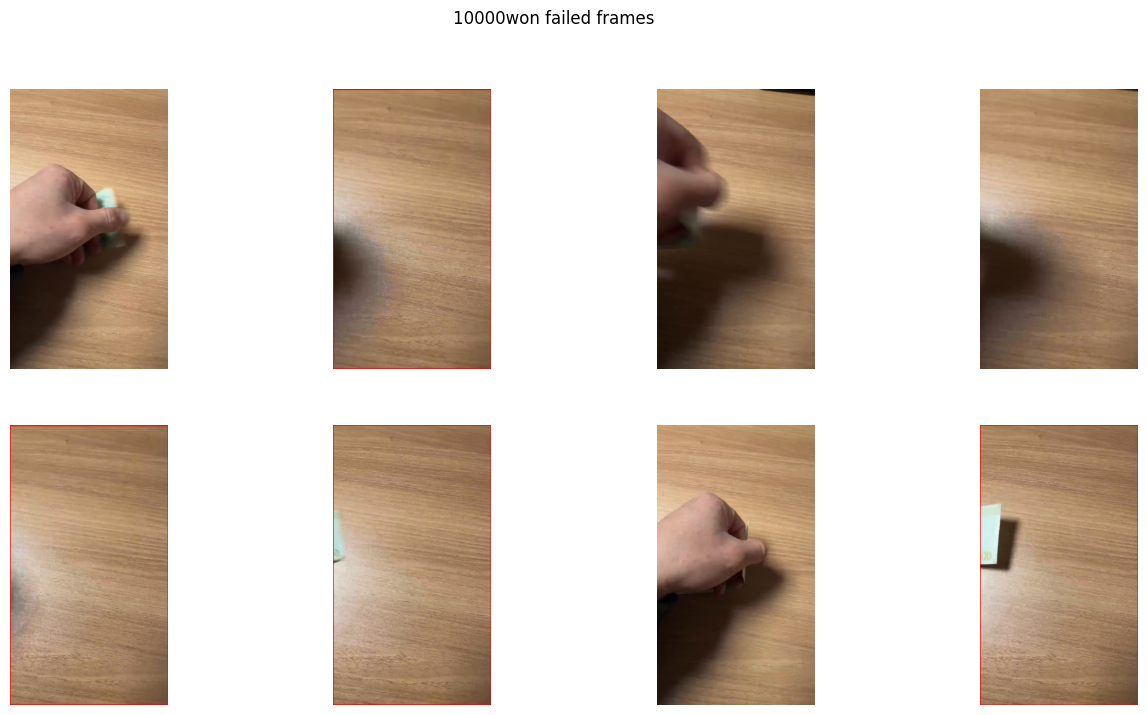

In [8]:
import cv2, glob, os, shutil, yaml, random
import matplotlib.pyplot as plt
from collections import Counter
from ultralytics import YOLO

N_PER_CLASS = 200
RAW = '/content/raw_frames'
shutil.rmtree(RAW, ignore_errors=True)
for c in CLASSES:
    src = glob.glob(f'{VIDEO_DIR}/{c}.*')[0]
    os.makedirs(f'{RAW}/{c}')
    cap = cv2.VideoCapture(src); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    step = max(1, total // N_PER_CLASS); i = k = 0
    while True:
        ok, f = cap.read()
        if not ok: break
        if i % step == 0:
            h, w = f.shape[:2]; s = 1280 / max(h, w)
            if s < 1: f = cv2.resize(f, (int(w * s), int(h * s)))
            cv2.imwrite(f'{RAW}/{c}/{k:04d}.jpg', f); k += 1
        i += 1

world = YOLO('yolov8x-worldv2.pt')
world.set_classes(['banknote', 'paper money', 'bill', 'money', 'cash', 'paper', 'card', 'document'])

labeled = {c: [] for c in CLASSES}
fails = {c: [] for c in CLASSES}
for ci, c in enumerate(CLASSES):
    why = Counter()
    for p in sorted(glob.glob(f'{RAW}/{c}/*.jpg')):
        r = world.predict(p, conf=0.01, verbose=False)[0]
        if len(r.boxes) == 0:
            why['탐지 없음'] += 1; fails[c].append((p, None)); continue
        j = int(r.boxes.conf.argmax())
        x, y, w, h = r.boxes.xywhn[j].tolist()
        if w * h <= 0.01:
            why['너무 작음'] += 1; fails[c].append((p, r.boxes.xyxy[j].tolist())); continue
        if w * h >= 0.98:
            why['화면 전체'] += 1; fails[c].append((p, r.boxes.xyxy[j].tolist())); continue
        labeled[c].append((p, f'{ci} {x:.6f} {y:.6f} {w:.6f} {h:.6f}'))
    print(f'{c}: 성공 {len(labeled[c])} / {len(glob.glob(f"{RAW}/{c}/*.jpg"))}  실패원인 {dict(why)}')

shutil.rmtree(DATA_DIR, ignore_errors=True)
for sp in ['train', 'valid', 'test']:
    os.makedirs(f'{DATA_DIR}/{sp}/images'); os.makedirs(f'{DATA_DIR}/{sp}/labels')
for c, items in labeled.items():
    n = len(items)
    for idx, (p, line) in enumerate(items):
        sp = 'train' if idx < 0.7 * n else ('valid' if idx < 0.9 * n else 'test')
        name = f'{c}_{os.path.basename(p)}'
        shutil.copy(p, f'{DATA_DIR}/{sp}/images/{name}')
        open(f'{DATA_DIR}/{sp}/labels/{name[:-4]}.txt', 'w').write(line + '\n')
yaml_path = f'{DATA_DIR}/data.yaml'
yaml.safe_dump({'path': DATA_DIR, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
                'names': {i: c for i, c in enumerate(CLASSES)}}, open(yaml_path, 'w'))
for sp in ['train', 'valid', 'test']:
    imgs = os.listdir(f'{DATA_DIR}/{sp}/images')
    print(sp, len(imgs), {c: sum(i.startswith(c + '_') for i in imgs) for c in CLASSES})
shutil.make_archive(f'{SAVE_DIR}/dataset', 'zip', DATA_DIR)

smp = random.sample(fails['10000won'], min(8, len(fails['10000won'])))
if smp:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, (p, b) in zip(axes.flat, smp):
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        if b: cv2.rectangle(img, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (255, 0, 0), 4)
        ax.imshow(img); ax.axis('off')
    plt.suptitle('10000won failed frames'); plt.show()

In [ ]:
import os, glob
for d in glob.glob('runs/detect/runs/*'):
    dst = f'runs/{os.path.basename(d)}'
    if not os.path.exists(dst):
        os.symlink(os.path.abspath(d), dst)
print(os.listdir('runs'))

1000won: 성공 210 / 211  실패원인 {'화면 전체': 1}
5000won: 성공 253 / 254  실패원인 {'화면 전체': 1}
10000won: 성공 239 / 252  실패원인 {'화면 전체': 5, '탐지 없음': 8}
train 493 {'1000won': 147, '5000won': 178, '10000won': 168}
valid 140 {'1000won': 42, '5000won': 50, '10000won': 48}
test 69 {'1000won': 21, '5000won': 25, '10000won': 23}


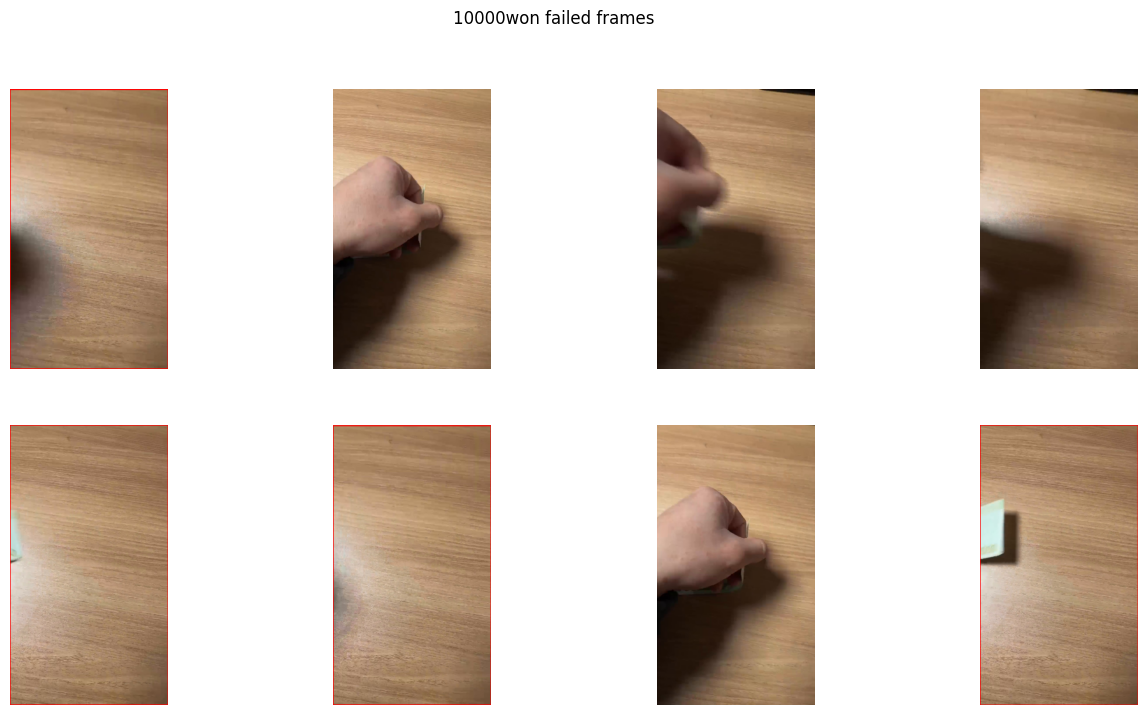

In [5]:
import cv2, glob, os, shutil, yaml, random
import matplotlib.pyplot as plt
from collections import Counter
from ultralytics import YOLO

N_PER_CLASS = 200
RAW = '/content/raw_frames'
shutil.rmtree(RAW, ignore_errors=True)
for c in CLASSES:
    src = glob.glob(f'{VIDEO_DIR}/{c}.*')[0]
    os.makedirs(f'{RAW}/{c}')
    cap = cv2.VideoCapture(src); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    step = max(1, total // N_PER_CLASS); i = k = 0
    while True:
        ok, f = cap.read()
        if not ok: break
        if i % step == 0:
            h, w = f.shape[:2]; s = 1280 / max(h, w)
            if s < 1: f = cv2.resize(f, (int(w * s), int(h * s)))
            cv2.imwrite(f'{RAW}/{c}/{k:04d}.jpg', f); k += 1
        i += 1

world = YOLO('yolov8x-worldv2.pt')
world.set_classes(['banknote', 'paper money', 'bill', 'money', 'cash', 'paper', 'card', 'document'])

labeled = {c: [] for c in CLASSES}
fails = {c: [] for c in CLASSES}
for ci, c in enumerate(CLASSES):
    why = Counter()
    for p in sorted(glob.glob(f'{RAW}/{c}/*.jpg')):
        r = world.predict(p, conf=0.01, verbose=False)[0]
        if len(r.boxes) == 0:
            why['탐지 없음'] += 1; fails[c].append((p, None)); continue
        j = int(r.boxes.conf.argmax())
        x, y, w, h = r.boxes.xywhn[j].tolist()
        if w * h <= 0.01:
            why['너무 작음'] += 1; fails[c].append((p, r.boxes.xyxy[j].tolist())); continue
        if w * h >= 0.98:
            why['화면 전체'] += 1; fails[c].append((p, r.boxes.xyxy[j].tolist())); continue
        labeled[c].append((p, f'{ci} {x:.6f} {y:.6f} {w:.6f} {h:.6f}'))
    print(f'{c}: 성공 {len(labeled[c])} / {len(glob.glob(f"{RAW}/{c}/*.jpg"))}  실패원인 {dict(why)}')

shutil.rmtree(DATA_DIR, ignore_errors=True)
for sp in ['train', 'valid', 'test']:
    os.makedirs(f'{DATA_DIR}/{sp}/images'); os.makedirs(f'{DATA_DIR}/{sp}/labels')
for c, items in labeled.items():
    n = len(items)
    for idx, (p, line) in enumerate(items):
        sp = 'train' if idx < 0.7 * n else ('valid' if idx < 0.9 * n else 'test')
        name = f'{c}_{os.path.basename(p)}'
        shutil.copy(p, f'{DATA_DIR}/{sp}/images/{name}')
        open(f'{DATA_DIR}/{sp}/labels/{name[:-4]}.txt', 'w').write(line + '\n')
yaml_path = f'{DATA_DIR}/data.yaml'
yaml.safe_dump({'path': DATA_DIR, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
                'names': {i: c for i, c in enumerate(CLASSES)}}, open(yaml_path, 'w'))
for sp in ['train', 'valid', 'test']:
    imgs = os.listdir(f'{DATA_DIR}/{sp}/images')
    print(sp, len(imgs), {c: sum(i.startswith(c + '_') for i in imgs) for c in CLASSES})
shutil.make_archive(f'{SAVE_DIR}/dataset', 'zip', DATA_DIR)

smp = random.sample(fails['10000won'], min(8, len(fails['10000won'])))
if smp:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, (p, b) in zip(axes.flat, smp):
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        if b: cv2.rectangle(img, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (255, 0, 0), 4)
        ax.imshow(img); ax.axis('off')
    plt.suptitle('10000won failed frames'); plt.show()

videos хавтас: ['1000won.mp4', '5000won.mp4', '10000won.mp4', 'demo.mp4', 'demo.gvid']
/content/drive/MyDrive/ML_assignment2/videos/demo.mp4 977 кадр | Tue Nov 24 10:54:37 2026
/content/result.mp4 → БАЙХГҮЙ
/content/drive/MyDrive/ML_assignment2/result.mp4 206 кадр | Tue Nov 24 07:50:23 2026


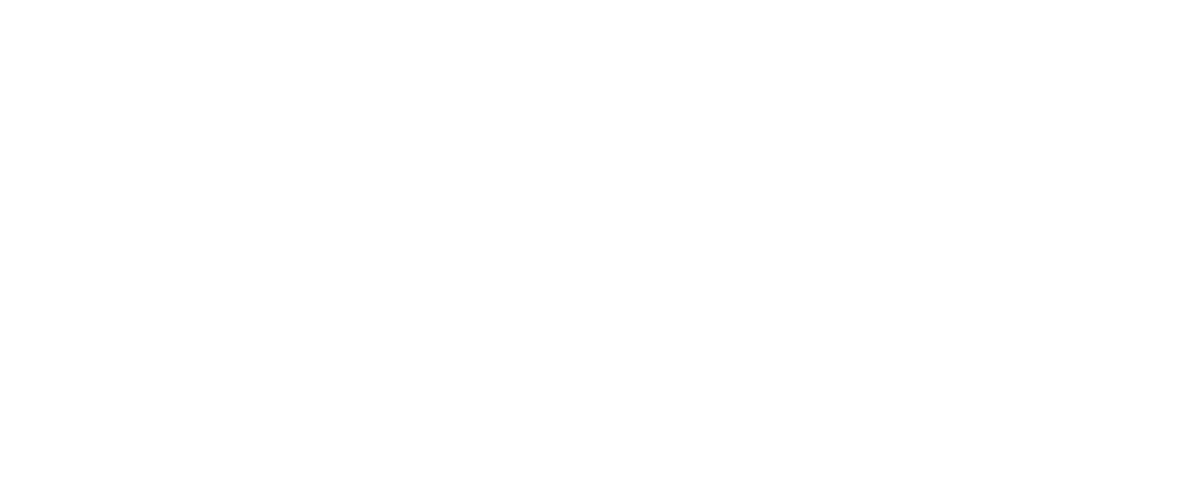

In [10]:
import os, cv2, time
import matplotlib.pyplot as plt
print('videos хавтас:', os.listdir(VIDEO_DIR))
for f in [f'{VIDEO_DIR}/demo.mp4', '/content/result.mp4', f'{SAVE_DIR}/result.mp4']:
    if os.path.exists(f):
        cap = cv2.VideoCapture(f)
        print(f, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), 'кадр |', time.ctime(os.path.getmtime(f)))
    else:
        print(f, '→ БАЙХГҮЙ')

cap = cv2.VideoCapture('/content/result.mp4')
n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, k in zip(axes, [n // 4, n // 2, n * 3 // 4]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, k); ok, f = cap.read()
    if ok: ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.show()

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x57bf0aff3a80] moov atom not found
[in#0 @ 0x57bf0aff3980] Error opening input: Invalid data found when processing input
Error opening input file /content/result_raw.mp4.
Error opening input files: Invalid data found when processing input
[in#0 @ 0x584654645940] Error opening input: No such file or directory
Error opening input file /content/result.mp4.
Error opening input files: No such file or directory
✅ best.pt 5.5MB
✅ results.png 0.3MB
❌ байхгүй: runs/detect/runs/test_pretrained/confusion_matrix.png
❌ байхгүй: runs/compare_curve.png
❌ байхгүй: runs/error_cases.png
❌ байхгүй: /content/result.mp4
❌ байхгүй: /content/result.gif
❌ байхгүй: /content/trajectory.csv


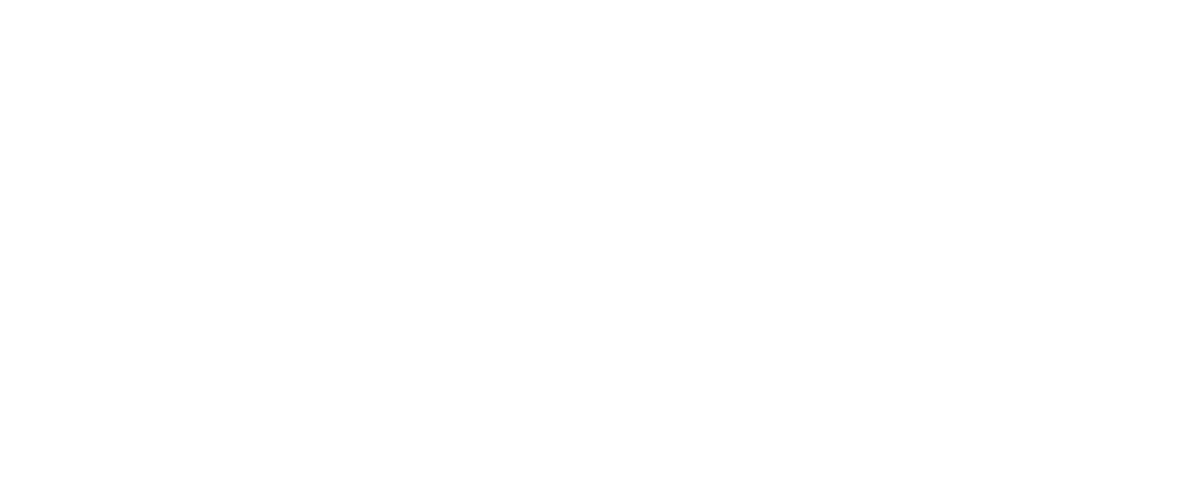

In [11]:
import os, glob, shutil, cv2
import matplotlib.pyplot as plt

# 1) Хөрвүүлэх (mp4 + README-д зориулсан GIF)
!ffmpeg -y -loglevel error -i /content/result_raw.mp4 -vcodec libx264 -pix_fmt yuv420p /content/result.mp4
!ffmpeg -y -loglevel error -i /content/result.mp4 -vf "fps=8,scale=400:-1" /content/result.gif

# 2) Бүх үр дүнг Drive-д хадгалах
R = 'runs/detect/runs'
files = [f'{R}/pretrained/weights/best.pt', f'{R}/pretrained/results.png',
         f'{R}/test_pretrained/confusion_matrix.png', 'runs/compare_curve.png',
         'runs/error_cases.png', '/content/result.mp4', '/content/result.gif',
         '/content/trajectory.csv']
if 'compare' in globals():
    compare.to_csv('/content/compare.csv', index=False); files.append('/content/compare.csv')
for f in files:
    if os.path.exists(f):
        shutil.copy(f, SAVE_DIR); print('✅', os.path.basename(f), f'{os.path.getsize(f)/1e6:.1f}MB')
    else:
        print('❌ байхгүй:', f)

# 3) Үр дүнгийн видеоноос 3 кадр харах
cap = cv2.VideoCapture('/content/result.mp4'); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, k in zip(axes, [n // 4, n // 2, n * 3 // 4]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, k); ok, f = cap.read()
    if ok: ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.show()

1-14 сек хайчилсан ✅
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2469.8±260.0 MB/s, size: 218.1 KB)
val: Scanning /content/dataset/test/labels.cache... 69 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 69/69 11.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.7it/s 1.9s
                   all         69         69      0.997          1      0.995      0.995
Speed: 2.6ms preprocess, 4.5ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/runs/detect/test_pretrained
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3369.0±687.2 MB/s, size: 215.0 K

,실험,Precision,Recall,mAP50,mAP50-95,AP 1000won,AP 5000won,AP 10000won
0,pretrained,0.997,1.0,0.995,0.995,0.995,0.995,0.995
1,scratch,0.997,1.0,0.995,0.969,0.995,0.991,0.921


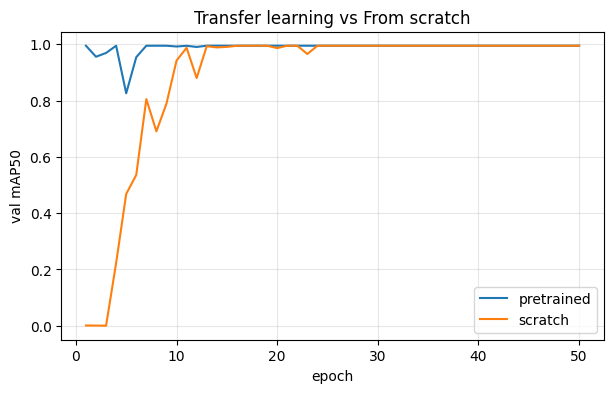

테스트 69장 중 오류 0장
처리한 프레임: 390
✅ best.pt 5.5MB
✅ compare.csv 0.0MB
✅ compare_curve.png 0.0MB
✅ confusion_matrix_pretrained.png 0.1MB
✅ confusion_matrix_scratch.png 0.1MB
✅ result.gif 9.9MB
✅ result.mp4 3.6MB
✅ results.png 0.3MB
✅ trajectory.csv 0.0MB


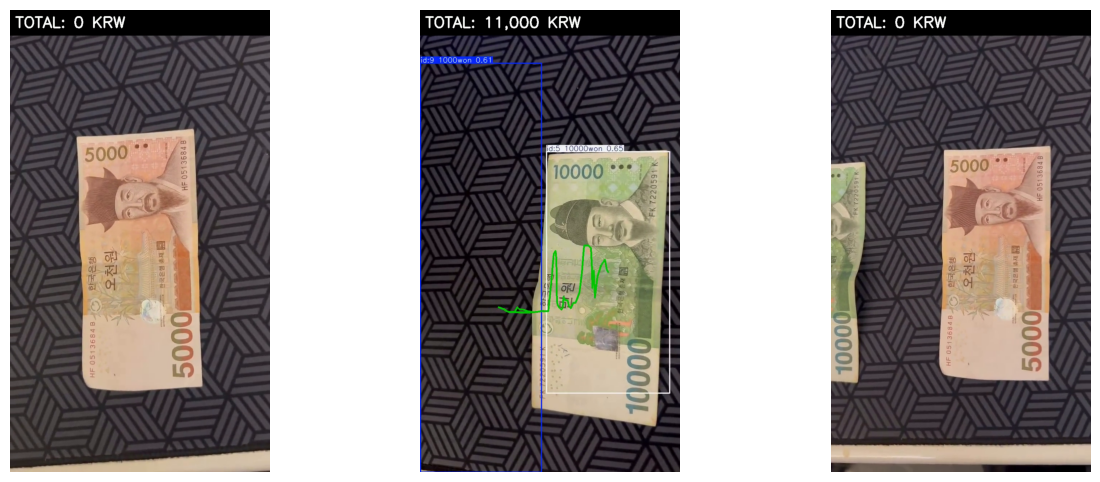

GIF: 5.1 MB ✅


<Figure size 640x480 with 0 Axes>

In [20]:
import shutil, os
src = f'{VIDEO_DIR}/demo.mp4'
bak = f'{VIDEO_DIR}/demo_full_backup.mp4'
if not os.path.exists(bak):
    shutil.copy(src, bak)
!ffmpeg -y -loglevel error -ss 1 -to 14 -i "{bak}" -an -c:v libx264 -pix_fmt yuv420p /content/demo_cut.mp4
shutil.copy('/content/demo_cut.mp4', src)
print('1-14 сек хайчилсан ✅')

%run -i /content/yolo_final.py

!ffmpeg -y -loglevel error -i /content/out/result.mp4 -vf "fps=6,scale=320:-1" /content/out/result.gif
shutil.copy('/content/out/result.gif', f'{SAVE_DIR}/results/')
print('GIF:', round(os.path.getsize('/content/out/result.gif') / 1e6, 1), 'MB ✅')

In [14]:
import os, glob, shutil, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict, deque
from ultralytics import YOLO
R = 'runs/detect/runs'
OUT = '/content/out'; os.makedirs(OUT, exist_ok=True)

# ---- 4) 성능 비교 ----
rows = []
for name in ['pretrained', 'scratch']:
    m = YOLO(f'{R}/{name}/weights/best.pt')
    r = m.val(data=yaml_path, split='test', name=f'test_{name}', exist_ok=True, verbose=False)
    row = {'실험': name, 'Precision': round(r.box.mp, 3), 'Recall': round(r.box.mr, 3),
           'mAP50': round(r.box.map50, 3), 'mAP50-95': round(r.box.map, 3)}
    for c in r.box.ap_class_index:
        row[f'AP {m.names[int(c)]}'] = round(r.box.maps[int(c)], 3)
    rows.append(row)
    cms = sorted(glob.glob(f'runs/**/test_{name}/confusion_matrix.png', recursive=True), key=os.path.getmtime)
    if cms: shutil.copy(cms[-1], f'{OUT}/confusion_matrix_{name}.png')
compare = pd.DataFrame(rows); compare.to_csv(f'{OUT}/compare.csv', index=False)
display(compare)

# ---- 학습 곡선 ----
plt.figure(figsize=(7, 4))
for name in ['pretrained', 'scratch']:
    df = pd.read_csv(f'{R}/{name}/results.csv'); df.columns = df.columns.str.strip()
    plt.plot(df['epoch'], df['metrics/mAP50(B)'], label=name)
plt.xlabel('epoch'); plt.ylabel('val mAP50'); plt.title('Transfer learning vs From scratch')
plt.legend(); plt.grid(alpha=.3); plt.savefig(f'{OUT}/compare_curve.png', dpi=150, bbox_inches='tight'); plt.show()
shutil.copy(f'{R}/pretrained/results.png', f'{OUT}/results.png')
shutil.copy(f'{R}/pretrained/weights/best.pt', f'{OUT}/best.pt')

# ---- 5) 오류 분석 ----
best = YOLO(f'{R}/pretrained/weights/best.pt'); names = best.names
tests = sorted(glob.glob(f'{DATA_DIR}/test/images/*')); errors = []
for p in tests:
    lbl = os.path.splitext(p.replace('/images/', '/labels/'))[0] + '.txt'
    gt = sorted(int(l.split()[0]) for l in open(lbl) if l.strip())
    r = best.predict(p, conf=0.5, verbose=False)[0]
    pred = sorted(r.boxes.cls.int().tolist())
    if gt != pred: errors.append(([names[i] for i in gt], [names[i] for i in pred], r))
print(f'테스트 {len(tests)}장 중 오류 {len(errors)}장')
if errors:
    n = min(6, len(errors)); fig, axes = plt.subplots(1, n, figsize=(4 * n, 4)); axes = np.atleast_1d(axes)
    for ax, (gt, pred, r) in zip(axes, errors[:n]):
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.set_title(f'GT: {gt}\nPred: {pred}', fontsize=9); ax.axis('off')
    plt.savefig(f'{OUT}/error_cases.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 6) 데모 영상: 탐지 + 추적 + 궤적 + 총 금액 ----
VALUE = {'1000won': 1000, '5000won': 5000, '10000won': 10000}
COLORS = {'1000won': (255, 120, 0), '5000won': (0, 80, 255), '10000won': (0, 200, 0)}
cap = cv2.VideoCapture(f'{VIDEO_DIR}/demo.mp4')
fps = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read(); H, W = frame.shape[:2]
out = cv2.VideoWriter('/content/result_raw.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
hist = defaultdict(lambda: deque(maxlen=int(fps * 2))); log = []; fi = 0
while ok:
    r = best.track(frame, persist=True, tracker='bytetrack.yaml', conf=0.4, verbose=False)[0]
    vis = r.plot(line_width=2); total = 0; cnt = defaultdict(int)
    if r.boxes.id is not None:
        for (x, y, w, h), tid, c in zip(r.boxes.xywh.cpu().numpy(), r.boxes.id.int().tolist(), r.boxes.cls.int().tolist()):
            cn = names[c]; total += VALUE[cn]; cnt[cn] += 1
            hist[tid].append((int(x), int(y))); log.append((fi, tid, cn, float(x), float(y)))
            cv2.polylines(vis, [np.array(hist[tid], np.int32).reshape(-1, 1, 2)], False, COLORS[cn], 3)
    cv2.rectangle(vis, (0, 0), (W, 70), (0, 0, 0), -1)
    cv2.putText(vis, f'TOTAL: {total:,} KRW', (15, 48), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255,

_IncompleteInputError: incomplete input (3084498193.py, line 66)

In [16]:
from google.colab import files
files.upload()


Saving yolo_final.py to yolo_final (1).py


{'yolo_final (1).py': b'import os, glob, shutil, cv2, numpy as np, pandas as pd\nimport matplotlib.pyplot as plt\nfrom collections import defaultdict, deque\nfrom ultralytics import YOLO\nR = \'runs/detect/runs\'\nOUT = \'/content/out\'; os.makedirs(OUT, exist_ok=True)\n\n# ---- 4) \xec\x84\xb1\xeb\x8a\xa5 \xeb\xb9\x84\xea\xb5\x90 ----\nrows = []\nfor name in [\'pretrained\', \'scratch\']:\n    m = YOLO(f\'{R}/{name}/weights/best.pt\')\n    r = m.val(data=yaml_path, split=\'test\', name=f\'test_{name}\', exist_ok=True, verbose=False)\n    row = {\'\xec\x8b\xa4\xed\x97\x98\': name, \'Precision\': round(r.box.mp, 3), \'Recall\': round(r.box.mr, 3),\n           \'mAP50\': round(r.box.map50, 3), \'mAP50-95\': round(r.box.map, 3)}\n    for c in r.box.ap_class_index:\n        row[f\'AP {m.names[int(c)]}\'] = round(r.box.maps[int(c)], 3)\n    rows.append(row)\n    cms = sorted(glob.glob(f\'runs/**/test_{name}/confusion_matrix.png\', recursive=True), key=os.path.getmtime)\n    if cms: shutil.c

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1982.7±715.5 MB/s, size: 185.7 KB)
val: Scanning /content/dataset/test/labels.cache... 69 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 69/69 17.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7it/s 2.9s
                   all         69         69      0.997          1      0.995      0.995
Speed: 3.2ms preprocess, 6.6ms inference, 0.0ms loss, 5.2ms postprocess per image
Results saved to /content/runs/detect/test_pretrained
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2696.6±411.2 MB/s, size: 201.9 KB)
val: Scanning /con

,실험,Precision,Recall,mAP50,mAP50-95,AP 1000won,AP 5000won,AP 10000won
0,pretrained,0.997,1.0,0.995,0.995,0.995,0.995,0.995
1,scratch,0.997,1.0,0.995,0.969,0.995,0.991,0.921


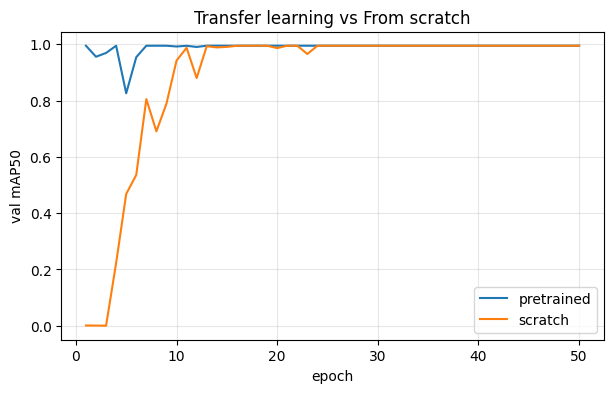

테스트 69장 중 오류 0장
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 196ms
Prepared 1 package in 31ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

처리한 프레임: 977
✅ best.pt 5.5MB
✅ compare.csv 0.0MB
✅ compare_curve.png 0.0MB
✅ confusion_matrix_pretrained.png 0.1MB
✅ confusion_matrix_scratch.png 0.1MB
✅ result.gif 25.3MB
✅ result.mp4 10.6MB
✅ results.png 0.3MB
✅ trajectory.csv 0.1MB


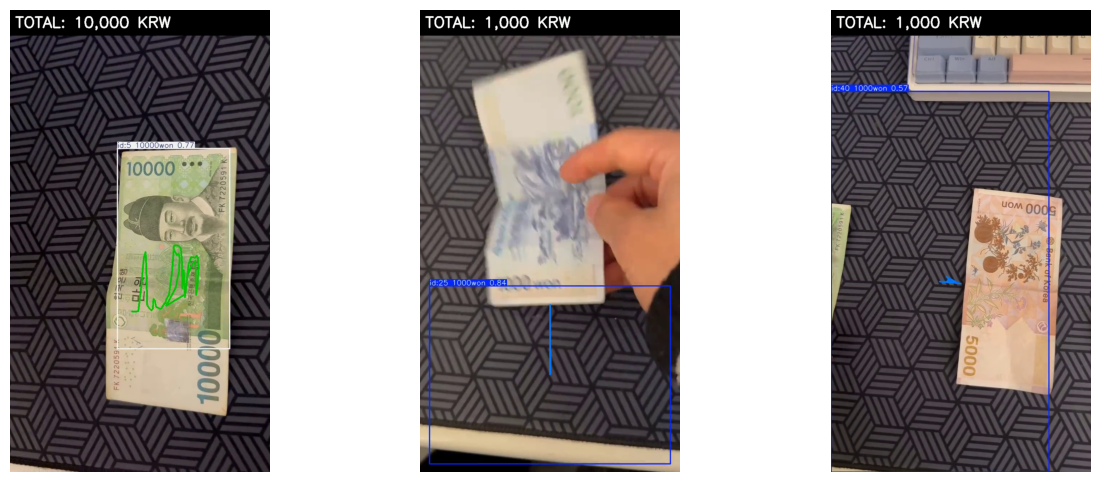

<Figure size 640x480 with 0 Axes>

In [19]:
%run -i /content/yolo_final.py

In [18]:
from ultralytics import YOLO
m = YOLO('yolo11n.yaml')
m.train(data=yaml_path, epochs=50, imgsz=640,
        batch=16, hsv_h=0.0, fliplr=0.0, seed=0,
        project='runs', name='scratch',
        exist_ok=True, pretrained=False)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=scratch, nbs=64, nms=None, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x77fa19ba8980>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04